# PGR215 – Data Collection and Analysis
## NYC Yellow & Green Taxi Trips, 2020–2024

End-to-end pipeline: scraping the TLC download links, converting parquet to CSV,
cleaning with PySpark, backing the cleaned data up into SQLite, then EDA and plots.

Section headings below follow the exam brief (Parts A–E).


## Setup

`requests` + `BeautifulSoup` for the scrape, `pandas` (pyarrow backend) for reading the
parquet files and writing CSV, `os` for the folder checks and `time` for the delay
between downloads.


In [1]:
import requests
from bs4 import BeautifulSoup as bs
import os 
import time
import pandas as pd


## Part A.1 — Scraping the download links

The TLC page lists every monthly file as a normal link, so the URLs can be scraped
instead of hard-coded.

Two things needed working around:

- A plain `requests.get()` came back with access denied, so a browser `User-Agent`
  header is set.
- The `href` values have a trailing space, which breaks the request — hence `.strip()`.

The files for each year live in a `<div>` with id `faq2020` … `faq2024`, so only those
five ids are searched. Anchors are filtered on their `title` attribute rather than the
link text, keeping only the yellow and green trip record links. Result: 120 URLs
(5 years × 12 months × 2 taxi types) in `parquet_urls`.


In [2]:
headers = {'User-Agent':'Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/141.0.0.0 Safari/537.36 OPR/125.0.0.0'} #because usual request was returning access denied
url = 'https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page'
request = requests.get(url,headers=headers)
if request.status_code == 200:
    html_soup = bs(request.text,'html.parser')
    years = [f'faq202{s}'for s in range(0,5)]
    div = html_soup.find_all(name='div',id=years)
    div = str(div)[1:-1] 
    links = bs(div,'html.parser')
    links = links.find_all(href = True)
    parquet_urls = []
    for a in links:
        if a.get('title') in ("Green Taxi Trip Records","Yellow Taxi Trip Records"):
            parquet_urls.append(a.get('href').strip())
    #len(parquet_urls)
    #parquet_urls



### Downloading, integrity check, and conversion to CSV (A.1 + A.2)

`file_check_up()` runs *before* any download. It compares the number of files already in
`trip_data/` against the number of scraped URLs, then tries to open each one with
`pd.read_parquet`. Anything that raises is treated as corrupted and gets re-downloaded.
This makes the notebook safe to re-run and catches partial downloads instead of carrying
a broken file into the next stage.

`transform_to_csv()` handles A.2. Each parquet file is read and written out to
`trip_data_csv/`, then read back and its row count compared against the source so a
truncated write would be caught. `low_memory=False` is needed on the read-back: pandas
reads CSVs in chunks by default and was warning about mismatched dtypes between chunks.

The download loop streams in 1 MB chunks and sleeps 10 seconds between files. Without the
sleep the server starts returning 403 — `curl` checks from a terminal showed the same
link failing and then working again a moment later, which pointed to rate limiting rather
than a bad URL.


In [3]:
def file_check_up():
    if os.path.isdir('trip_data'):
        name_list = os.listdir('trip_data')
        if len(name_list) != len(parquet_urls):
            name_list = []
    else:
        name_list = []

    if len(name_list) != len(parquet_urls):
        print(f'{len(name_list)}/{len(parquet_urls)} files present — need to download.')
        return None
    failed=0
    failed_files=[]
    if name_list:
        for file in name_list:
            file_path = f'trip_data/{file}'
            try:
                df = pd.read_parquet(file_path)
                #print(df.head())
            except:
                failed+=1
                failed_files.append(file)

        print('Failed to load:',failed,'file.')
        return failed_files

def transform_to_csv():
    files = os.listdir('trip_data')
    folder = os.makedirs('trip_data_csv',exist_ok=True)
    done=0
    if os.path.isdir('trip_data_csv') and len(os.listdir('trip_data'))==len(os.listdir('trip_data_csv')):
        print('files already transformed')
        return
    else:
        for file in files:
            csv_path = f'trip_data_csv/{file.replace('.parquet','.csv')}'
            df = pd.read_parquet(f'trip_data/{file}')
            df.to_csv(csv_path,index = False)
            csv_df = pd.read_csv(csv_path, low_memory=False)
            if len(csv_df) == len(df):
                done += 1
                print(f'{done}/{len(files)} is done')
            else:
                print(f'{file} failed to transform to csv')

failed_files = file_check_up()
if failed_files:
    
    done=0
    folder = os.makedirs("trip_data", exist_ok=True)
    files_to_download = []
    for f in parquet_urls:
        if f.split('/')[-1] in failed_files or failed_files is None:
            files_to_download.append(f)



    for file in files_to_download:
        name = file.split('/')[-1]
        done +=1
        with requests.get(file,stream=True,headers = headers) as data:
            with open(f'trip_data/{name}','wb') as f: 
                for chunk in data.iter_content(chunk_size=1024*1024):
                    f.write(chunk)
            print('left:',len(files_to_download)-done)
            time.sleep(10)
    failed_files = file_check_up()
    print('failed to download after the download process')
else:
    print('All the files are ready')
    print('Transforming files to csv')
    transform_to_csv()









Failed to load: 0 file.
All the files are ready
Transforming files to csv
files already transformed


## Part B — Spark setup

Imports for the PySpark stage plus `sqlite3` for Part C.


In [4]:
import findspark
from pyspark import SparkContext, SparkConf
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
import sqlite3

### B.1 — Creating the Spark session

8 GB driver memory, 4 GB executor memory and a 4 GB `maxResultSize`. The larger driver
memory is needed because the SQLite write in Part C collects data back to the driver.


In [5]:
findspark.init()

spark = SparkSession \
    .builder \
    .appName("Exam") \
    .config("spark.driver.memory", "8g") \
    .config("spark.executor.memory", "4g") \
    .config("spark.driver.maxResultSize", "4g")\
    .getOrCreate()

if 'spark' in locals() and isinstance(spark, SparkSession):
    print("SparkSession is active and ready to use.")
else:
    print("SparkSession is not active. Please create a SparkSession.")

spark

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/misaki/programming/Uni/Data collection and analysis/.venv/lib/python3.14/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/08/06 01:38:53 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


SparkSession is active and ready to use.


### First look at the data

One yellow and one green file loaded so the two schemas can be compared before building
anything on top of them. `inferSchema=True` means Spark reads each file twice (once for
types, once for data), which is slower than a defined schema — but the columns aren't
identical across yellow, green and all five years, so inference is the pragmatic choice.


In [6]:
yellow_tripdata = spark.read.csv('trip_data_csv/yellow_tripdata_2020-01.csv',sep=',',inferSchema=True,header=True)
green_tripdata = spark.read.csv('trip_data_csv/green_tripdata_2020-01.csv',sep=',',inferSchema=True,header=True)
yellow_tripdata.show()

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|airport_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+
|       1| 2020-01-01 00:28:15|  2020-01-01 00:33:03|            1.0|          1.2|       1.0|                 N|         238|         239|           1|        6.0|  3.0|    0.5|      1.4

### Pipeline functions

All the pipeline logic in one cell. What each function does:

**`all_for_one()`** — lists the CSV folder, splits filenames on their `yellow_`/`green_`
prefix, reads each into a DataFrame and unions them. `unionByName` is used rather than
plain `union` because `union` matches on column *position*, and the column order could be not
identical across all five years — it would silently line up the wrong columns.
`allowMissingColumns=True` handles fields that appear partway through the period
(e.g. `airport_fee`) by filling them with null.

**`null_handle(df)`** — drops `ehail_fee` entirely (green-only, effectively always
empty). Drops rows missing `passenger_count`, `RatecodeID`, `store_and_fwd_flag` or
`congestion_surcharge`, since those are filtered on later and can't sensibly be guessed.
`airport_fee` is filled with 0 rather than dropped, because a missing value there means
"no airport fee applied", not "unknown" or the column was introduced later. As discovering data, I noticed, that it was indeed introduced after 2020. so whole table of 2020 had no such column.

**`data_cleanup(df)`** — renames the datetime columns to neutral names (`pickup_col` /
`dropoff_col`), since yellow uses the `tpep_` prefix and green uses `lpep_`. That rename
is what makes it possible to run identical filters and identical SQL against both fleets.
Raises if neither pair is found, so a malformed file fails loudly.

Two derived columns are added: `time_spent` (dropoff − pickup, in hours) and `speed`
(`trip_distance / time_spent`, via `try_divide` so a zero duration yields null instead of
an error). Speed turned out to be the most useful field for catching bad records — a trip
reading 3000 mph is obviously a meter or clock error even when every individual column
looks valid.

The filter block then removes: dates outside 2020–2024, invalid vendor / rate code /
payment type values, passenger counts outside 1–10, non-positive or absurd distances,
surcharges outside their fixed ranges, non-positive totals, sub-minute durations, and
implausible speeds. Note the split ceiling on `fare_amount`: rate codes 4 (Nassau/
Westchester) and 5 (negotiated) legitimately produce high fares, so they get $1500 while
everything else is capped at $1000.

**`to_sql(df_y, df_g)`** — writes to `nyc_taxi.db` one *month* at a time rather than one
year at a time. A single year of yellow data is far too large to collect into the driver
with `.toPandas()`. January uses `if_exists='replace'` and the rest append, so each yearly
table is built from twelve small collects.

**`check_sql()`** — counts rows in the cleaned DataFrames and compares against what's
already in the database. If they match, the load is skipped; if the database doesn't
exist yet the exception handler returns `True` so the load runs. Same idea as
`file_check_up()` — re-running shouldn't repeat hours of work.

**`ETL()`** — chains the above with progress printing logs and the percentage of rows
lost at the cleaning stage.


In [7]:
def all_for_one():
    files = os.listdir('trip_data_csv')
    green_files = [f for f in files if f.startswith('green_tripdata_') and f.endswith('.csv')]
    yellow_files = [f for f in files if f.startswith('yellow_tripdata_') and f.endswith('.csv')]

    dfs = [spark.read.csv(f'trip_data_csv/{f}', header=True, inferSchema=True) for f in yellow_files]
    yellow_all = dfs[0]
    for df in dfs[1:]:
        yellow_all = yellow_all.unionByName(df, allowMissingColumns=True)

    dfs = [spark.read.csv(f'trip_data_csv/{f}', header=True, inferSchema=True) for f in green_files]
    green_all = dfs[0]
    for df in dfs[1:]:
        green_all = green_all.unionByName(df, allowMissingColumns=True)

    return yellow_all,green_all

def null_handle(df):
    if 'ehail_fee' in df.columns:
        df = df.drop('ehail_fee')

    df_cleaned = df.dropna(subset=['passenger_count','RatecodeID','store_and_fwd_flag','congestion_surcharge'])
    try:
        df_filled = df_cleaned.fillna(0,'airport_fee')
        return df_filled
    except:
        return df_cleaned

def data_cleanup(df):
    if 'tpep_pickup_datetime' in df.columns:
        df = df.withColumnRenamed('tpep_pickup_datetime','pickup_col').withColumnRenamed('tpep_dropoff_datetime','dropoff_col')
    elif 'lpep_pickup_datetime' in df.columns:
        df = df.withColumnRenamed('lpep_pickup_datetime','pickup_col').withColumnRenamed('lpep_dropoff_datetime','dropoff_col')
    else:
        raise ValueError("No recognized pickup/dropoff datetime columns found")
    try:
        df_normal_speed = df.withColumn('time_spent',
    (F.col('dropoff_col').cast('bigint')-F.col('pickup_col').cast('bigint'))/3600).withColumn('speed',
    (F.try_divide(F.col('trip_distance'), F.col('time_spent'))))
    except Exception as e:
        print('error in speed determination ',e)

    df_normal = df_normal_speed.filter(
        (F.year(F.col('pickup_col')).between(2020, 2024)) &
        (F.year(F.col('dropoff_col')).between(2020, 2024))&
        (F.col('VendorID').isin([1,2,6,7]))&
        (F.col('passenger_count').between(1,10))&
        (F.col('trip_distance')>0)&(F.col('trip_distance')<1000)&
        (F.col('RatecodeID').isin([1,2,3,4,5,6,99]))&
        (F.col('payment_type').isin([0,1,2,3,4,5,6]))&
        (((F.col('RatecodeID').isin([4, 5])) & (F.col('fare_amount') <= 1500)) | ((~F.col('RatecodeID').isin([4, 5])) & (F.col('fare_amount') <= 1000)))&
        (F.col('extra').between(0,10))&
        (F.col('mta_tax').between(0,1))&
        (F.col('tip_amount').between(0,300))&
        (F.col('tolls_amount').between(0,100))&
        (F.col('improvement_surcharge').between(0, 1))&
        (F.col('total_amount') > 0) & (F.col('total_amount') < 2000) &
        (F.col('congestion_surcharge').between(0, 5) )&
        (F.col('time_spent')>(1/60))&
        (F.col('speed')>=0.1)&
        (F.col('speed')<65)
        )
    return df_normal

def to_sql(df_y,df_g):
    if check_sql():
        print('data importing started!')
        conn = sqlite3.connect('nyc_taxi.db')
        for year in range(2020, 2025):
            for month in range(1, 13):
                mode = 'replace' if month == 1 else 'append'

                y_chunk = df_y.filter(
                    (F.year(F.col('pickup_col')) == year) & (F.month(F.col('pickup_col')) == month)
                ).toPandas()
                y_chunk.to_sql(f'yellow_{year}', conn, if_exists=mode, index=False)

                g_chunk = df_g.filter(
                    (F.year(F.col('pickup_col')) == year) & (F.month(F.col('pickup_col')) == month)
                ).toPandas()
                g_chunk.to_sql(f'green_{year}', conn, if_exists=mode, index=False)
        conn.close()
    else:
        return

def check_sql():
    try:
        yellow,green = all_for_one()
        conn = sqlite3.connect('nyc_taxi.db')
        yellow_csv = data_cleanup(null_handle((yellow))).count()
        green_csv = data_cleanup(null_handle((green))).count()
        cursor = conn.cursor()
        rows_y = 0
        rows_g=0
        for year in range(2020, 2025):
            cursor.execute(f"SELECT COUNT(*) FROM yellow_{year}")
            amount_y=cursor.fetchone()[0]
            rows_y += amount_y
            cursor.execute(f"SELECT COUNT(*) FROM green_{year}")
            amount_g = cursor.fetchone()[0]
            rows_g += amount_g
        conn.close()
        if rows_g == green_csv and rows_y==yellow_csv:
            print('data was already loaded and intact')
            return False
        else:
            return True
    except:
        print('DataBase was not created yet!')
        return True

def ETL():
    print('Start of ETL')
    print('Extracting data and combining it in one')
    try:
        yellow,green=all_for_one()
        yellow_total = yellow.count()
        green_total = green.count()
        print('Data succsessfully combined with output of yellow and green dataframe for yellow and green taxi corespondently')
    except Exception as e:
        print('failed to combine dataframes of green or yellow ',e)
        raise
    
    print('droping nulls in dfs')
    try:
        yellow = null_handle(yellow)
        green = null_handle(green)
        print('Nulls have been droped')
    except Exception as e:
        print('failed to drop nulls:', e)
        raise

    print('cleaning dataframe: dropping all the corrupted data')
    try:
        yellow_clean= data_cleanup(yellow)
        green_clean = data_cleanup(green)
        yellow_clean_total= yellow_clean.count()
        green_clean_total= green_clean.count()
        yellow_loss = (yellow_total-yellow_clean_total)/yellow_total*100
        green_loss= (green_total-green_clean_total)/green_total*100
        print(f'''Data has been cleaned with loss of:
        {yellow_loss:.2f}% of yellow dataframe and
        {green_loss:.2f}% of green''')
    except Exception as e:
        print('Failed to cleanup data\n',e)
        raise
    
    print('loading up data to sqlite.db')
    try:


        to_sql(yellow_clean,green_clean)
        print('DataFrames were loaded to db "nyc_taxi.db"')
    except Exception as e:
        print('Couldnt save it to db', e)
        raise
    print('ETL pipeline has successfully finished with db created and yellow_clean and green_clean dataframes created.')
    return yellow_clean, green_clean

### Comparing the two schemas

The two fleets don't have the same columns. Yellow has `airport_fee` and the `tpep_`
datetime prefix; green has `trip_type`, `ehail_fee` and the `lpep_` prefix. This is what
the rename in `data_cleanup()` is solving.


In [8]:
print(set(yellow_tripdata.columns)-set(green_tripdata.columns))
print(yellow_tripdata.columns)
print(green_tripdata.columns)

{'tpep_pickup_datetime', 'airport_fee', 'tpep_dropoff_datetime'}
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'airport_fee']
['VendorID', 'lpep_pickup_datetime', 'lpep_dropoff_datetime', 'store_and_fwd_flag', 'RatecodeID', 'PULocationID', 'DOLocationID', 'passenger_count', 'trip_distance', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'ehail_fee', 'improvement_surcharge', 'total_amount', 'payment_type', 'trip_type', 'congestion_surcharge']


### B.3 — Consolidated DataFrames

`yellow_all` and `green_all`: all 60 monthly files per fleet unioned into one DataFrame
each.


In [9]:
yellow_all,green_all = all_for_one()

In [10]:
null_counts = yellow_all.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in yellow_all.columns
])
null_counts.show()

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|airport_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+
|       0|                   0|                    0|        9057553|            0|   9057553|           9057553|           0|           0|           0|          0|    0|      0|         

In [11]:
yellow_all.groupBy(F.year('tpep_pickup_datetime').alias('year')) \
    .agg(F.count(F.when(F.col('airport_fee').isNull(), 1)).alias('null_airport_fee'),
         F.count("*").alias('total')) \
    .orderBy("year").show()

    #airport_fee had extra amounts of nulls. so had to check and as it is shown in the table in 2020 this stable was missing met another issue. i have typos or errors so i have 2001-2070 years.

+----+----------------+--------+
|year|null_airport_fee|   total|
+----+----------------+--------+
|2001|               0|      12|
|2002|               1|     465|
|2003|               2|      27|
|2004|               0|       1|
|2008|              41|     185|
|2009|             117|     366|
|2011|               0|       4|
|2012|               0|       1|
|2014|               0|       1|
|2019|             131|     131|
|2020|        24648807|24648828|
|2021|         5641390|30903982|
|2022|         1368303|39655622|
|2023|         1309356|38310138|
|2024|         4091232|41169670|
|2025|               0|       5|
|2026|               0|       2|
|2028|               0|       1|
|2029|               0|       1|
|2070|               0|       1|
+----+----------------+--------+
only showing top 20 rows


In [13]:
yellow_all.describe().show()

26/08/05 23:52:47 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+------------------+------------------+-----------------+------------------+------------------+------------------+------------------+------------------+------------------+-----------------+-------------------+------------------+-----------------+---------------------+------------------+--------------------+-------------------+
|summary|          VendorID|   passenger_count|    trip_distance|        RatecodeID|store_and_fwd_flag|      PULocationID|      DOLocationID|      payment_type|       fare_amount|            extra|            mta_tax|        tip_amount|     tolls_amount|improvement_surcharge|      total_amount|congestion_surcharge|        airport_fee|
+-------+------------------+------------------+-----------------+------------------+------------------+------------------+------------------+------------------+------------------+-----------------+-------------------+------------------+-----------------+---------------------+------------------+--------------------+----------

### Running the full ETL

Arrow is disabled for the pandas conversion here — it was causing problems on the large
collects. This cell runs the whole pipeline: combine → drop nulls → filter → write to
SQLite, and prints how much data each stage removed.


In [10]:
#Final run!
spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "false")
yellow_clean, green_clean = ETL()

Start of ETL
Extracting data and combining it in one


Data succsessfully combined with output of yellow and green dataframe for yellow and green taxi corespondently
droping nulls in dfs
Nulls have been droped
cleaning dataframe: dropping all the corrupted data


26/08/06 01:41:42 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
26/08/06 01:41:43 WARN DAGScheduler: Broadcasting large task binary with size 1618.9 KiB
26/08/06 01:43:06 WARN DAGScheduler: Broadcasting large task binary with size 1656.6 KiB


Data has been cleaned with loss of:
        9.30% of yellow dataframe and
        30.28% of green
loading up data to sqlite.db


26/08/06 01:44:32 WARN DAGScheduler: Broadcasting large task binary with size 1618.9 KiB
26/08/06 01:45:54 WARN DAGScheduler: Broadcasting large task binary with size 1656.6 KiB


data was already loaded and intact
DataFrames were loaded to db "nyc_taxi.db"
ETL pipeline has successfully finished with db created and yellow_clean and green_clean dataframes created.


## Part C.3 — Verification queries

Sample rows from `yellow_2022`, confirming the tables were written and that both derived
columns (`time_spent`, `speed`) survived the round-trip.


In [11]:
conn = sqlite3.connect('nyc_taxi.db')
cursor = conn.cursor()

cursor.execute("SELECT * FROM yellow_2022 LIMIT 5")
for row in cursor.fetchall():
    print(row)

(2, '2022-01-08 20:51:58', '2022-01-08 21:23:50', 4.0, 4.9, 1.0, 'N', 166, 162, 1, 22.5, 0.0, 0.5, 5.16, 0.0, 0.3, 30.96, 2.5, 0.0, 0.5311111111111111, 9.225941422594143)
(2, '2022-01-08 21:34:04', '2022-01-08 21:40:08', 4.0, 1.16, 1.0, 'N', 233, 140, 2, 6.0, 0.0, 0.5, 0.0, 0.0, 0.3, 9.3, 2.5, 0.0, 0.10111111111111111, 11.472527472527473)
(2, '2022-01-30 04:48:26', '2022-01-30 05:11:09', 3.0, 3.36, 1.0, 'N', 262, 186, 1, 16.0, 0.0, 0.5, 3.86, 0.0, 0.3, 23.16, 2.5, 0.0, 0.3786111111111111, 8.874541452677915)
(2, '2022-01-30 05:18:31', '2022-01-30 05:23:19', 2.0, 0.67, 1.0, 'N', 107, 137, 1, 5.0, 0.0, 0.5, 2.08, 0.0, 0.3, 10.38, 2.5, 0.0, 0.08, 8.375)
(2, '2022-01-11 13:21:14', '2022-01-11 13:39:21', 2.0, 2.12, 1.0, 'N', 263, 233, 1, 12.5, 0.0, 0.5, 4.74, 0.0, 0.3, 20.54, 2.5, 0.0, 0.30194444444444446, 7.021159153633855)


### Column check

Confirms the renamed `pickup_col`/`dropoff_col` are in the database, and shows the
remaining schema difference between the two fleets.


In [12]:
cursor.execute("SELECT * FROM yellow_2020 LIMIT 0")
column_names = [description[0] for description in cursor.description]
print("yellow_2020 columns:", column_names)

cursor.execute("SELECT * FROM green_2020 LIMIT 0")
column_names_g = [description[0] for description in cursor.description]
print("green_2020 columns:", column_names_g)

yellow_2020 columns: ['VendorID', 'pickup_col', 'dropoff_col', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'airport_fee', 'time_spent', 'speed']
green_2020 columns: ['VendorID', 'pickup_col', 'dropoff_col', 'store_and_fwd_flag', 'RatecodeID', 'PULocationID', 'DOLocationID', 'passenger_count', 'trip_distance', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'payment_type', 'trip_type', 'congestion_surcharge', 'time_spent', 'speed']


### Date range check

Every yellow table should fall entirely inside its own year — this verifies the year
filter held through the write.


In [13]:
for year in range(2020, 2025):
    cursor.execute(f"SELECT MIN(pickup_col), MAX(pickup_col) FROM yellow_{year}")
    min_date, max_date = cursor.fetchone()
    print(f"yellow_{year}: {min_date} to {max_date}")

yellow_2020: 2020-01-01 00:00:00 to 2020-12-31 23:59:45
yellow_2021: 2021-01-01 00:00:04 to 2021-12-31 23:59:51
yellow_2022: 2022-01-01 00:00:08 to 2022-12-31 23:59:59
yellow_2023: 2023-01-01 00:00:05 to 2023-12-31 23:59:59
yellow_2024: 2024-01-01 00:00:00 to 2024-12-31 23:56:59


### Invalid distance check

Counts anything outside the distance filter. Should be 0 across all five tables.


In [14]:
for year in range(2020, 2025):
    cursor.execute(f"SELECT COUNT(*) FROM yellow_{year} WHERE trip_distance <= 0 OR trip_distance >= 1000")
    bad = cursor.fetchone()[0]
    print(f"yellow_{year}: {bad} rows with invalid trip_distance")

yellow_2020: 0 rows with invalid trip_distance
yellow_2021: 0 rows with invalid trip_distance
yellow_2022: 0 rows with invalid trip_distance
yellow_2023: 0 rows with invalid trip_distance
yellow_2024: 0 rows with invalid trip_distance


### Duplicate check

Compares total rows against distinct combinations of pickup time, dropoff time, distance
and fare in `yellow_2020`. The handful of matches that come back were left in — at this
volume, two cabs starting and ending at the same second with the same distance and fare
is possible, and a few hundred rows can't move any aggregate.


In [15]:
cursor.execute("""
    SELECT COUNT(*), COUNT(DISTINCT pickup_col || dropoff_col || trip_distance || fare_amount)
    FROM yellow_2020
""")
total, distinct = cursor.fetchone()
print(f"yellow_2020: {total:,} total rows, {distinct:,} distinct rows")

yellow_2020: 22,837,535 total rows, 22,837,365 distinct rows


### Schema difference as stored

Confirms `airport_fee` is yellow-only and `trip_type` is green-only in the database.


In [16]:
yellow_cols = set(column_names)
green_cols = set(column_names_g)
print("Only in Yellow:", yellow_cols - green_cols)
print("Only in Green:", green_cols - yellow_cols)

Only in Yellow: {'airport_fee'}
Only in Green: {'trip_type'}


## Part D — Exploratory Data Analysis

Registering both cleaned DataFrames as temp views so the analysis can be written in SQL.


In [17]:
yellow_clean.createOrReplaceTempView('yellow')
green_clean.createOrReplaceTempView('green')

### D.1 — Average fare per trip


In [18]:
print('yellow avg fare:')
spark.sql('SELECT AVG(fare_amount) as avg_fare FROM yellow').show()

print('green avg fare:')
spark.sql('SELECT AVG(fare_amount) as avg_fare FROM green').show()

yellow avg fare:


26/08/06 01:47:18 WARN DAGScheduler: Broadcasting large task binary with size 1636.4 KiB


+-----------------+
|         avg_fare|
+-----------------+
|16.16685074215015|
+-----------------+

green avg fare:


26/08/06 01:48:33 WARN DAGScheduler: Broadcasting large task binary with size 1674.2 KiB


+------------------+
|          avg_fare|
+------------------+
|15.022080717718744|
+------------------+



### D.2 — Top 5 pickup locations

Raw `PULocationID` values. These have not been joined against the TLC taxi zone lookup
table — the IDs would need mapping to zone names for the report.


In [19]:
print('yellow top 5 pickup:')
spark.sql('''
SELECT PULocationID, COUNT(*) as count FROM yellow
GROUP BY PULocationID ORDER BY count DESC LIMIT 5
''').show()

print('green top 5 pickup:')
spark.sql('''
SELECT PULocationID, COUNT(*) as count FROM green
GROUP BY PULocationID ORDER BY count DESC LIMIT 5
''').show()

yellow top 5 pickup:


26/08/06 01:48:38 WARN DAGScheduler: Broadcasting large task binary with size 2.5 MiB
26/08/06 01:50:07 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB


+------------+-------+
|PULocationID|  count|
+------------+-------+
|         237|7795026|
|         132|7055590|
|         236|6992911|
|         161|6839198|
|         186|5529539|
+------------+-------+

green top 5 pickup:


26/08/06 01:50:08 WARN DAGScheduler: Broadcasting large task binary with size 2.6 MiB


+------------+------+
|PULocationID| count|
+------------+------+
|          74|620928|
|          75|456276|
|          41|244378|
|         166|186166|
|          95|167968|
+------------+------+



26/08/06 01:50:12 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB


### D.3 — Fare and tip distribution by payment type

Note when reading the tip column: cash tips go straight to the driver and never reach the
meter, so payment type 2 records them as effectively zero. That's a property of how the
data is collected, not a real finding about cash customers.


In [20]:
print('yellow fare/tip by payment_type:')
spark.sql('''
SELECT payment_type, AVG(fare_amount) as avg_fare, AVG(tip_amount) as avg_tip, COUNT(*) as count
FROM yellow GROUP BY payment_type ORDER BY payment_type
''').show()

print('green fare/tip by payment_type:')
spark.sql('''
SELECT payment_type, AVG(fare_amount) as avg_fare, AVG(tip_amount) as avg_tip, COUNT(*) as count
FROM green GROUP BY payment_type ORDER BY payment_type
''').show()

yellow fare/tip by payment_type:


26/08/06 01:50:14 WARN DAGScheduler: Broadcasting large task binary with size 2.5 MiB
26/08/06 01:51:43 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB


+------------+------------------+--------------------+---------+
|payment_type|          avg_fare|             avg_tip|    count|
+------------+------------------+--------------------+---------+
|           1|16.296115703283277|    3.72180870731409|126447302|
|           2| 15.52448280371098|2.461047305554816E-4| 30758206|
|           3|16.692032264075642|0.004836545647996571|   499069|
|           4|20.445552303948425|0.015660127541459117|   736388|
|           5|15.733333333333333|                 0.0|       15|
+------------+------------------+--------------------+---------+

green fare/tip by payment_type:


26/08/06 01:51:44 WARN DAGScheduler: Broadcasting large task binary with size 2.6 MiB


+------------+------------------+--------------------+-------+
|payment_type|          avg_fare|             avg_tip|  count|
+------------+------------------+--------------------+-------+
|         1.0|15.822889420320287|   2.936742212600365|2185293|
|         2.0|13.758008049581282|1.270520529752462...|1355350|
|         3.0|10.818385374534861|0.007116971363856982|   6181|
|         4.0|10.665867469879515|0.001028112449799...|   2490|
|         5.0| 17.09767441860465|                 0.0|     43|
+------------+------------------+--------------------+-------+



26/08/06 01:51:49 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB


### D.4 — Weekday vs weekend trip frequency

`dayofweek()` in Spark returns 1 for Sunday and 7 for Saturday, so those two are the
weekend. Worth remembering when comparing the totals that weekday covers five days and
weekend only two.


In [21]:
print('yellow weekday vs weekend:')
spark.sql('''
SELECT CASE WHEN dayofweek(pickup_col) IN (1,7) THEN 'weekend' ELSE 'weekday' END as day_type, COUNT(*) as count
FROM yellow GROUP BY day_type
''').show()

print('green weekday vs weekend:')
spark.sql('''
SELECT CASE WHEN dayofweek(pickup_col) IN (1,7) THEN 'weekend' ELSE 'weekday' END as day_type, COUNT(*) as count
FROM green GROUP BY day_type
''').show()

yellow weekday vs weekend:


26/08/06 01:51:50 WARN DAGScheduler: Broadcasting large task binary with size 2.6 MiB
26/08/06 01:53:25 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB


+--------+---------+
|day_type|    count|
+--------+---------+
| weekday|116587316|
| weekend| 41853664|
+--------+---------+

green weekday vs weekend:


26/08/06 01:53:26 WARN DAGScheduler: Broadcasting large task binary with size 2.6 MiB


+--------+-------+
|day_type|  count|
+--------+-------+
| weekday|2667138|
| weekend| 882219|
+--------+-------+



26/08/06 01:53:31 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB


## Part E — Data Visualization


In [22]:
'''Part E: Data Visualization (15 Marks)'''

import matplotlib.pyplot as plt
import seaborn as sns

### E.1 — Year-wise trip trends, 2021–2024

Aggregation happens in Spark; only the small result (four rows per fleet) is pulled into
pandas. Both series on one axis so the two can be compared directly.


/home/misaki/programming/Uni/Data collection and analysis/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/08/06 01:53:33 WARN DAGScheduler: Broadcasting large task binary with size 2.5 MiB
26/08/06 01:55:08 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB
26/08/06 01:55:08 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB
26/08/06 01:55:08 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB
/home/misaki/programming/Uni/Data collection and analysis/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/08/06 01:55:1

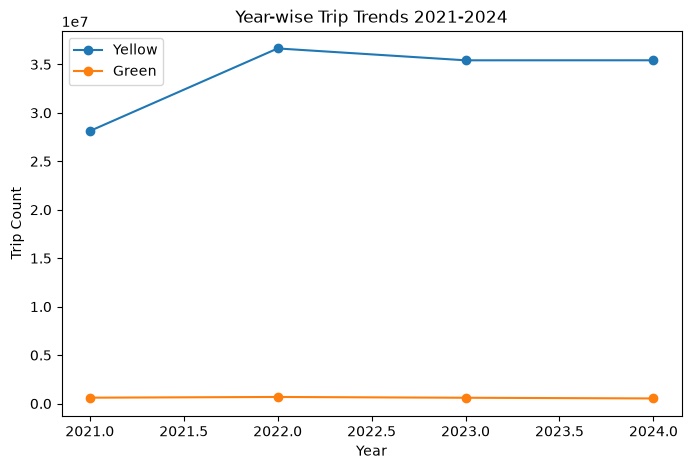

In [23]:
yellow_yearly = spark.sql('''
    SELECT year(pickup_col) as year, COUNT(*) as trip_count
    FROM yellow WHERE year(pickup_col) BETWEEN 2021 AND 2024
    GROUP BY year ORDER BY year
''').toPandas()

green_yearly = spark.sql('''
    SELECT year(pickup_col) as year, COUNT(*) as trip_count
    FROM green WHERE year(pickup_col) BETWEEN 2021 AND 2024
    GROUP BY year ORDER BY year''').toPandas()

plt.figure(figsize=(8,5))
plt.plot(yellow_yearly['year'],yellow_yearly['trip_count'],marker='o',label='Yellow')
plt.plot(green_yearly['year'],green_yearly['trip_count'],marker='o',label='Green')
plt.xlabel('Year')
plt.ylabel('Trip Count')
plt.title('Year-wise Trip Trends 2021-2024')
plt.legend()
plt.show()

### E.2 — Hourly trip distribution

Pickup hour extracted with `hour()`, counted in Spark, plotted as two bar charts side by
side on a shared layout.


/home/misaki/programming/Uni/Data collection and analysis/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/08/06 01:55:16 WARN DAGScheduler: Broadcasting large task binary with size 2.5 MiB
26/08/06 01:56:44 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB
26/08/06 01:56:45 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB
26/08/06 01:56:45 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB
/home/misaki/programming/Uni/Data collection and analysis/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/08/06 01:56:4

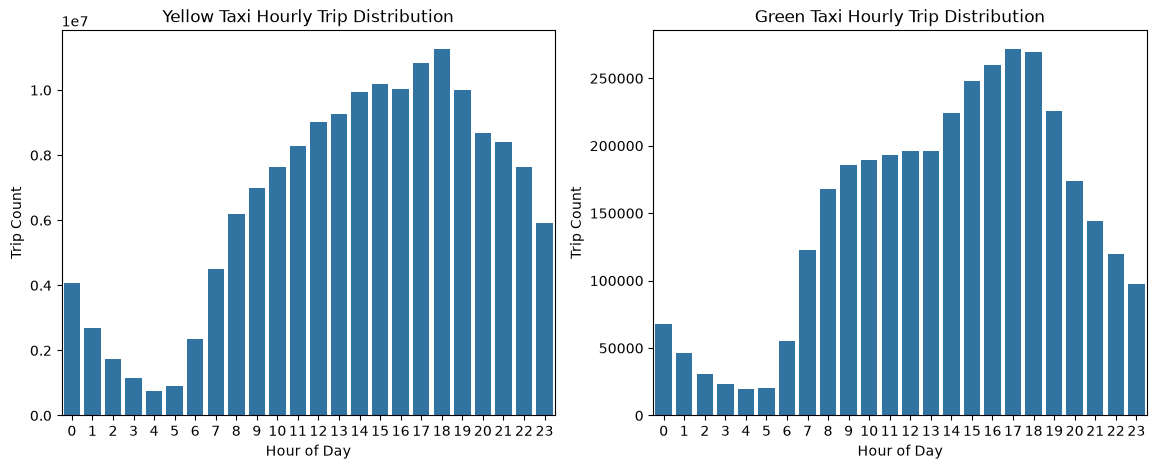

In [24]:
yellow_hourly = spark.sql('''
    SELECT hour(pickup_col) as hour, COUNT(*) as trip_count
    FROM yellow GROUP BY hour ORDER BY hour
''').toPandas()

green_hourly = spark.sql('''
    SELECT hour(pickup_col) as hour, COUNT(*) as trip_count
    FROM green GROUP BY hour ORDER BY hour
''').toPandas()

fig,axes = plt.subplots(1,2,figsize=(14,5))
sns.barplot(x='hour',y='trip_count',data=yellow_hourly,ax=axes[0])
axes[0].set_title('Yellow Taxi Hourly Trip Distribution')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Trip Count')

sns.barplot(x='hour',y='trip_count',data=green_hourly,ax=axes[1])
axes[1].set_title('Green Taxi Hourly Trip Distribution')
axes[1].set_xlabel('Hour of Day')
axes[1].set_ylabel('Trip Count')
plt.show()

### E.3 — Histogram of fare amounts

Rather than collecting 158 million fare values, the fares are bucketed into $5 bands in
Spark (`FLOOR(fare_amount/5)*5`) and only the bucket counts are pulled into pandas.


/home/misaki/programming/Uni/Data collection and analysis/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/08/06 01:56:53 WARN DAGScheduler: Broadcasting large task binary with size 2.6 MiB
26/08/06 01:58:22 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB
26/08/06 01:58:22 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB
26/08/06 01:58:23 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB
/home/misaki/programming/Uni/Data collection and analysis/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/08/06 01:58:2

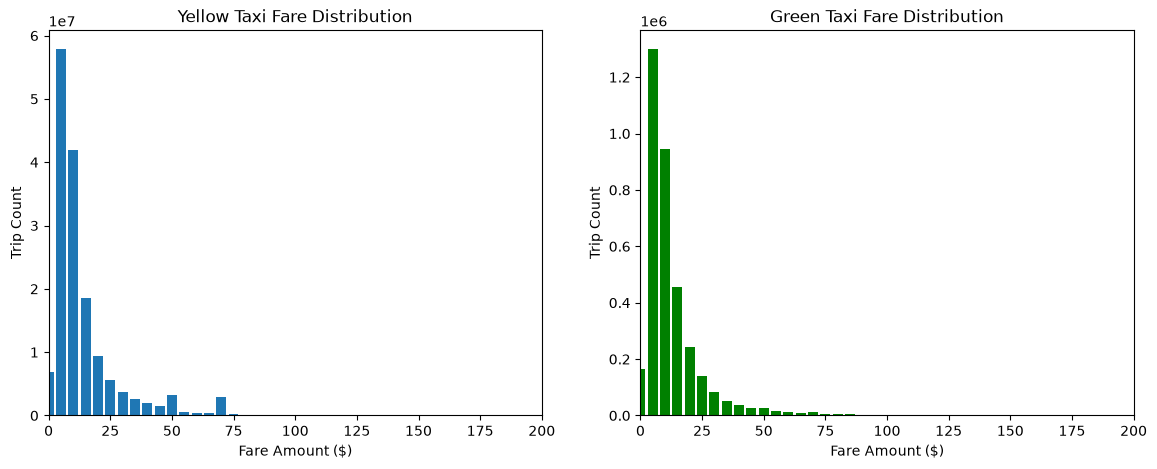

In [25]:
yellow_fare_bins = spark.sql('''
    SELECT CAST(FLOOR(fare_amount/5)*5 AS INT) as fare_bucket, COUNT(*) as count
    FROM yellow GROUP BY fare_bucket ORDER BY fare_bucket
''').toPandas()

green_fare_bins = spark.sql('''
    SELECT CAST(FLOOR(fare_amount/5)*5 AS INT) as fare_bucket, COUNT(*) as count
    FROM green GROUP BY fare_bucket ORDER BY fare_bucket
''').toPandas()

fig,axes = plt.subplots(1,2,figsize=(14,5))
axes[0].bar(yellow_fare_bins['fare_bucket'],yellow_fare_bins['count'],width=4)
axes[0].set_title('Yellow Taxi Fare Distribution')
axes[0].set_xlabel('Fare Amount ($)')
axes[0].set_ylabel('Trip Count')
axes[0].set_xlim(0,200)

axes[1].bar(green_fare_bins['fare_bucket'],green_fare_bins['count'],width=4,color='green')
axes[1].set_title('Green Taxi Fare Distribution')
axes[1].set_xlabel('Fare Amount ($)')
axes[1].set_ylabel('Trip Count')
axes[1].set_xlim(0,200)
plt.show()

### E.4 — Most used payment methods

Payment type codes mapped to readable labels and plotted per fleet.

/home/misaki/programming/Uni/Data collection and analysis/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/08/06 01:59:40 WARN DAGScheduler: Broadcasting large task binary with size 2.5 MiB
26/08/06 02:00:59 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB
26/08/06 02:01:00 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB
26/08/06 02:01:00 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB
/home/misaki/programming/Uni/Data collection and analysis/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/08/06 02:01:0

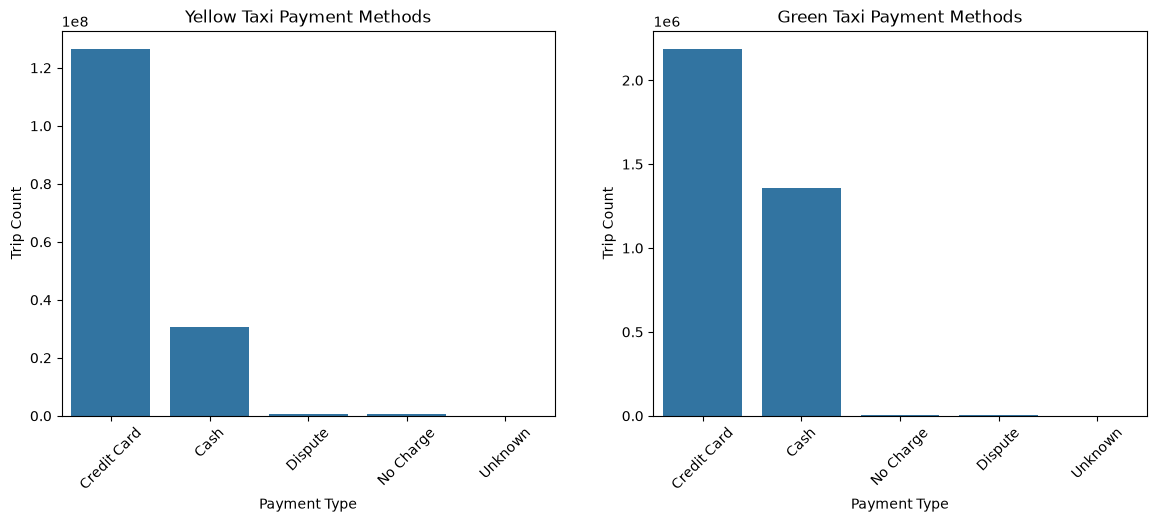

In [27]:
#4. most used payment methods
payment_labels = {1:'Credit Card',2:'Cash',3:'No Charge',4:'Dispute',5:'Unknown',6:'Voided',0:'Unknown'}

yellow_payment = spark.sql('''
    SELECT payment_type, COUNT(*) as count FROM yellow GROUP BY payment_type ORDER BY count DESC
''').toPandas()
yellow_payment['Payment Type'] = yellow_payment['payment_type'].map(payment_labels)

green_payment = spark.sql('''
    SELECT payment_type, COUNT(*) as count FROM green GROUP BY payment_type ORDER BY count DESC
''').toPandas()
green_payment['Payment Type'] = green_payment['payment_type'].map(payment_labels)

fig,axes = plt.subplots(1,2,figsize=(14,5))
sns.barplot(x='Payment Type',y='count',data=yellow_payment,ax=axes[0])
axes[0].set_title('Yellow Taxi Payment Methods')
axes[0].set_ylabel('Trip Count')
axes[0].tick_params(axis='x',rotation=45)

sns.barplot(x='Payment Type',y='count',data=green_payment,ax=axes[1])
axes[1].set_title('Green Taxi Payment Methods')
axes[1].set_ylabel('Trip Count')
axes[1].tick_params(axis='x',rotation=45)
plt.show()